<a href="https://colab.research.google.com/github/RajalakshmiTharmaraj/ProjectNew/blob/main/Model_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install -q pandas openpyxl

import pandas as pd
import numpy as np

from google.colab import files

# Upload v20 Excel file
uploaded = files.upload()

file_path = list(uploaded.keys())[0]
print("Uploaded file:", file_path)

Saving Thoothukudi_ML_Required_Dataset_2015_2025_v20.xlsx to Thoothukudi_ML_Required_Dataset_2015_2025_v20.xlsx
Uploaded file: Thoothukudi_ML_Required_Dataset_2015_2025_v20.xlsx


In [3]:
monthly = pd.read_excel(
    file_path,
    sheet_name="Monthly_Integrated_2015_2025"
)

print("Shape:", monthly.shape)
monthly.head()

Shape: (132, 50)


,Date,Year,Month,Season,Rainfall_mm,Max_Temp_C,Min_Temp_C,Avg_Temp_C,Avg_Humidity_pct,GW_Monthly_Avg_Level_m_bgl,...,Agri_Scenario_Type,Agri_Scenario_Final_Y_Status,Residential_Lower_Scenario_Monthly_ML,Residential_Upper_Scenario_Monthly_ML,Residential_Mid_Scenario_Monthly_ML,Agri_plus_Residential_Lower_Scenario_ML,Agri_plus_Residential_Upper_Scenario_ML,Agri_plus_Residential_Mid_Scenario_ML,Combined_Scenario_Type,Combined_Final_Y_Status
0,2015-01-01,2015,January,Winter,1.2,30.2,23.1,26.65,79.5,6.2725,...,Derived Scenario / Estimated Proxy,Not to use as final observed Y,3979.603343,5216.486925,4598.045134,3979.603343,5216.486925,4598.045134,Derived Scenario / Estimated Proxy,Not to use as final observed total Y
1,2015-02-01,2015,February,Winter,2.2,31.0,23.4,27.20,76.5,NaN,...,Derived Scenario / Estimated Proxy,Not to use as final observed Y,3594.480439,4711.665610,4153.073024,3594.480439,4711.665610,4153.073024,Derived Scenario / Estimated Proxy,Not to use as final observed total Y
2,2015-03-01,2015,March,Hot Weather,11.4,32.5,25.0,28.75,76.5,NaN,...,Derived Scenario / Estimated Proxy,Not to use as final observed Y,3979.603343,5216.486925,4598.045134,3979.603343,5216.486925,4598.045134,Derived Scenario / Estimated Proxy,Not to use as final observed total Y
3,2015-04-01,2015,April,Hot Weather,24.6,34.1,26.2,30.15,74.5,NaN,...,Derived Scenario / Estimated Proxy,Not to use as final observed Y,3851.229042,5048.213153,4449.721098,3851.229042,5048.213153,4449.721098,Derived Scenario / Estimated Proxy,Not to use as final observed total Y
4,2015-05-01,2015,May,Hot Weather,13.5,36.4,27.5,31.95,71.0,7.6050,...,Derived Scenario / Estimated Proxy,Not to use as final observed Y,3979.603343,5216.486925,4598.045134,3979.603343,5216.486925,4598.045134,Derived Scenario / Estimated Proxy,Not to use as final observed total Y


In [4]:
required_columns = [
    "Agri_Net_Water_Scenario_ML",
    "Residential_Lower_Scenario_Monthly_ML",
    "Residential_Upper_Scenario_Monthly_ML"
]

for col in required_columns:
    print(col, "->", col in monthly.columns)

Agri_Net_Water_Scenario_ML -> True
Residential_Lower_Scenario_Monthly_ML -> True
Residential_Upper_Scenario_Monthly_ML -> True


In [6]:
monthly["Residential_Mid_Scenario_Monthly_ML"] = (
    monthly["Residential_Lower_Scenario_Monthly_ML"] +
    monthly["Residential_Upper_Scenario_Monthly_ML"]
) / 2

In [7]:
monthly["Agri_Residential_Mid_Scenario_ML"] = (
    monthly["Agri_Net_Water_Scenario_ML"] +
    monthly["Residential_Mid_Scenario_Monthly_ML"]
)

In [8]:
target_column = "Agri_Residential_Mid_Scenario_ML"

y = monthly[target_column]

print("Target variable created successfully")
print(y.head(12))

Target variable created successfully
0      4598.045134
1      4153.073024
2      4598.045134
3      4449.721098
4      4598.045134
5     16941.580098
6     16492.049734
7     15541.614534
8     42558.639526
9      4598.045134
10     4449.721098
11    48047.568363
Name: Agri_Residential_Mid_Scenario_ML, dtype: float64


In [9]:
print("Number of rows:", len(y))
print("Missing target values:", y.isna().sum())

print("\nTarget statistics:")
print(y.describe())

Number of rows: 132
Missing target values: 0

Target statistics:
count       132.000000
mean      34033.169932
std       39635.153332
min        4153.073024
25%        4684.268772
50%       14229.830318
75%       42964.812226
max      135665.839878
Name: Agri_Residential_Mid_Scenario_ML, dtype: float64


In [10]:
monthly["Target_Value_Type"] = "Derived Scenario / Estimated Proxy"

monthly["Target_Status"] = (
    "Preliminary ML target - not total district water demand"
)

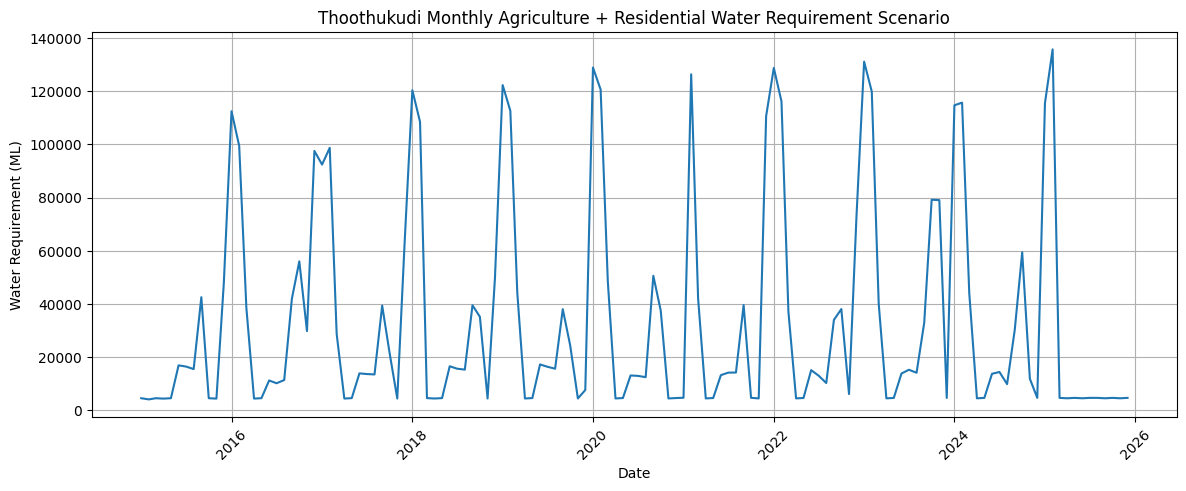

In [11]:
import matplotlib.pyplot as plt

monthly["Date"] = pd.to_datetime(monthly["Date"])

plt.figure(figsize=(14, 5))

plt.plot(
    monthly["Date"],
    monthly["Agri_Residential_Mid_Scenario_ML"]
)

plt.xlabel("Date")
plt.ylabel("Water Requirement (ML)")
plt.title(
    "Thoothukudi Monthly Agriculture + Residential "
    "Water Requirement Scenario"
)

plt.xticks(rotation=45)
plt.grid(True)
plt.show()

In [12]:
output_columns = [
    "Date",
    "Year",
    "Month",
    "Agri_Net_Water_Scenario_ML",
    "Residential_Mid_Scenario_Monthly_ML",
    "Agri_Residential_Mid_Scenario_ML",
    "Target_Value_Type",
    "Target_Status"
]

target_dataset = monthly[output_columns]

target_dataset.to_csv(
    "Thoothukudi_Target_Variable_2015_2025.csv",
    index=False
)

target_dataset.head(12)

,Date,Year,Month,Agri_Net_Water_Scenario_ML,Residential_Mid_Scenario_Monthly_ML,Agri_Residential_Mid_Scenario_ML,Target_Value_Type,Target_Status
0,2015-01-01,2015,January,0.000000,4598.045134,4598.045134,Derived Scenario / Estimated Proxy,Preliminary ML target - not total district wat...
1,2015-02-01,2015,February,0.000000,4153.073024,4153.073024,Derived Scenario / Estimated Proxy,Preliminary ML target - not total district wat...
2,2015-03-01,2015,March,0.000000,4598.045134,4598.045134,Derived Scenario / Estimated Proxy,Preliminary ML target - not total district wat...
3,2015-04-01,2015,April,0.000000,4449.721098,4449.721098,Derived Scenario / Estimated Proxy,Preliminary ML target - not total district wat...
4,2015-05-01,2015,May,0.000000,4598.045134,4598.045134,Derived Scenario / Estimated Proxy,Preliminary ML target - not total district wat...
5,2015-06-01,2015,June,12491.859000,4449.721098,16941.580098,Derived Scenario / Estimated Proxy,Preliminary ML target - not total district wat...
6,2015-07-01,2015,July,11894.004600,4598.045134,16492.049734,Derived Scenario / Estimated Proxy,Preliminary ML target - not total district wat...
7,2015-08-01,2015,August,10943.569400,4598.045134,15541.614534,Derived Scenario / Estimated Proxy,Preliminary ML target - not total district wat...
8,2015-09-01,2015,September,38108.918429,4449.721098,42558.639526,Derived Scenario / Estimated Proxy,Preliminary ML target - not total district wat...
9,2015-10-01,2015,October,0.000000,4598.045134,4598.045134,Derived Scenario / Estimated Proxy,Preliminary ML target - not total district wat...


In [13]:
files.download(
    "Thoothukudi_Target_Variable_2015_2025.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
y = monthly["Agri_Residential_Mid_Scenario_ML"]

In [17]:
import pandas as pd
import numpy as np
import calendar

from google.colab import files

uploaded = files.upload()
file_path = list(uploaded.keys())[0]

monthly = pd.read_excel(
    file_path,
    sheet_name="Monthly_Integrated_2015_2025"
)

agriculture = pd.read_excel(
    file_path,
    sheet_name="Agriculture_Annual_Features"
)

monthly["Date"] = pd.to_datetime(monthly["Date"])

print(monthly.shape)
monthly.head()

Saving Thoothukudi_ML_Required_Dataset_2015_2025_v20.xlsx to Thoothukudi_ML_Required_Dataset_2015_2025_v20 (1).xlsx
(132, 50)


,Date,Year,Month,Season,Rainfall_mm,Max_Temp_C,Min_Temp_C,Avg_Temp_C,Avg_Humidity_pct,GW_Monthly_Avg_Level_m_bgl,...,Agri_Scenario_Type,Agri_Scenario_Final_Y_Status,Residential_Lower_Scenario_Monthly_ML,Residential_Upper_Scenario_Monthly_ML,Residential_Mid_Scenario_Monthly_ML,Agri_plus_Residential_Lower_Scenario_ML,Agri_plus_Residential_Upper_Scenario_ML,Agri_plus_Residential_Mid_Scenario_ML,Combined_Scenario_Type,Combined_Final_Y_Status
0,2015-01-01,2015,January,Winter,1.2,30.2,23.1,26.65,79.5,6.2725,...,Derived Scenario / Estimated Proxy,Not to use as final observed Y,3979.603343,5216.486925,4598.045134,3979.603343,5216.486925,4598.045134,Derived Scenario / Estimated Proxy,Not to use as final observed total Y
1,2015-02-01,2015,February,Winter,2.2,31.0,23.4,27.20,76.5,NaN,...,Derived Scenario / Estimated Proxy,Not to use as final observed Y,3594.480439,4711.665610,4153.073024,3594.480439,4711.665610,4153.073024,Derived Scenario / Estimated Proxy,Not to use as final observed total Y
2,2015-03-01,2015,March,Hot Weather,11.4,32.5,25.0,28.75,76.5,NaN,...,Derived Scenario / Estimated Proxy,Not to use as final observed Y,3979.603343,5216.486925,4598.045134,3979.603343,5216.486925,4598.045134,Derived Scenario / Estimated Proxy,Not to use as final observed total Y
3,2015-04-01,2015,April,Hot Weather,24.6,34.1,26.2,30.15,74.5,NaN,...,Derived Scenario / Estimated Proxy,Not to use as final observed Y,3851.229042,5048.213153,4449.721098,3851.229042,5048.213153,4449.721098,Derived Scenario / Estimated Proxy,Not to use as final observed total Y
4,2015-05-01,2015,May,Hot Weather,13.5,36.4,27.5,31.95,71.0,7.6050,...,Derived Scenario / Estimated Proxy,Not to use as final observed Y,3979.603343,5216.486925,4598.045134,3979.603343,5216.486925,4598.045134,Derived Scenario / Estimated Proxy,Not to use as final observed total Y


In [18]:
crop_specs = {

    "Paddy_ha": {
        "depth": 575,
        "months": [6, 7, 8, 9, 10, 11, 12, 1]
    },

    "Maize_ha": {
        "depth": 650,
        "months": [10, 11, 12, 1, 2]
    },

    "Blackgram_ha": {
        "depth": 400,
        "months": [9, 10, 11, 12, 1, 2, 3]
    },

    "Greengram_ha": {
        "depth": 400,
        "months": [9, 10, 11, 12, 1, 2, 3]
    },

    "Cholam_ha": {
        "depth": 550,
        "months": [10, 11, 12, 1, 2]
    },

    "Cumbu_ha": {
        "depth": 550,
        "months": [10, 11, 12, 1, 2]
    },

    "Groundnut_ha": {
        "depth": 600,
        "months": [6, 7, 8, 9, 10, 11, 12, 1]
    }
}

In [19]:
agriculture["Start_Year"] = (
    agriculture["Year"]
    .astype(str)
    .str[:4]
    .astype(int)
)

agriculture_by_year = (
    agriculture
    .set_index("Start_Year")
    .to_dict("index")
)

In [20]:
print(agriculture_by_year.keys())

dict_keys([2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024])


In [22]:
agri_results = []

for i, row in monthly.iterrows():

    year = int(row["Year"])
    month_name = row["Month"]

    month_num = list(calendar.month_name).index(
        month_name
    )

    rainfall = row["Rainfall_mm"]

    # Agricultural year:
    # June-Dec -> current year
    # Jan-May  -> previous year

    if month_num >= 6:
        crop_year = year
    else:
        crop_year = year - 1

    # ---------------------------------------
    # Check whether crop-year data exists
    # ---------------------------------------

    if crop_year not in agriculture_by_year:

        agri_results.append({
            "Agri_Gross_Water_Scenario_ML": np.nan,
            "Agri_Effective_Rainfall_Proxy_ML": np.nan,
            "Agri_Net_Water_Scenario_ML": np.nan,
            "Agri_Active_Crop_Count": 0,
            "Agri_Water_Status":
                "No crop-year data available"
        })

        continue

    crop_data = agriculture_by_year[crop_year]

    gross = 0.0
    effective_rainfall = 0.0
    active_crop_count = 0

    # ---------------------------------------
    # Calculate crop requirements
    # ---------------------------------------

    for crop, spec in crop_specs.items():

        area = crop_data.get(crop, np.nan)

        if pd.isna(area):
            continue

        # Crop not active in this month
        if month_num not in spec["months"]:
            continue

        active_crop_count += 1

        monthly_depth = (
            spec["depth"] /
            len(spec["months"])
        )

        crop_gross = (
            area *
            monthly_depth *
            0.01
        )

        effective_depth = min(
            monthly_depth,
            rainfall * 0.80
        )

        crop_effective_rainfall = (
            area *
            effective_depth *
            0.01
        )

        gross += crop_gross
        effective_rainfall += crop_effective_rainfall

    # =======================================
    # IMPORTANT CORRECTION
    # =======================================

    if active_crop_count == 0:

        gross_value = np.nan
        rainfall_value = np.nan
        net_value = np.nan

        status = "No active crop coverage"

    else:

        gross_value = gross
        rainfall_value = effective_rainfall

        net_value = max(
            gross - effective_rainfall,
            0
        )

        if np.isclose(net_value, 0):

            net_value = 0

            status = (
                "Rainfall satisfied estimated "
                "crop requirement"
            )

        else:

            status = (
                "Estimated irrigation requirement"
            )

    agri_results.append({

        "Agri_Gross_Water_Scenario_ML":
            gross_value,

        "Agri_Effective_Rainfall_Proxy_ML":
            rainfall_value,

        "Agri_Net_Water_Scenario_ML":
            net_value,

        "Agri_Active_Crop_Count":
            active_crop_count,

        "Agri_Water_Status":
            status
    })

In [23]:
agri_corrected = pd.DataFrame(
    agri_results
)

for col in agri_corrected.columns:

    monthly[col] = agri_corrected[col].values

In [24]:
monthly[
    [
        "Date",
        "Rainfall_mm",
        "Agri_Active_Crop_Count",
        "Agri_Net_Water_Scenario_ML",
        "Agri_Water_Status"
    ]
].head(20)

,Date,Rainfall_mm,Agri_Active_Crop_Count,Agri_Net_Water_Scenario_ML,Agri_Water_Status
0,2015-01-01,1.2,0,NaN,No crop-year data available
1,2015-02-01,2.2,0,NaN,No crop-year data available
2,2015-03-01,11.4,0,NaN,No crop-year data available
3,2015-04-01,24.6,0,NaN,No crop-year data available
4,2015-05-01,13.5,0,NaN,No crop-year data available
5,2015-06-01,8.5,2,12491.859000,Estimated irrigation requirement
6,2015-07-01,12.4,2,11894.004600,Estimated irrigation requirement
7,2015-08-01,18.6,2,10943.569400,Estimated irrigation requirement
8,2015-09-01,20.5,4,38108.918429,Estimated irrigation requirement
9,2015-10-01,218.4,7,0.000000,Rainfall satisfied estimated crop requirement


In [25]:
print(
    monthly["Agri_Water_Status"]
    .value_counts(dropna=False)
)

Agri_Water_Status
Estimated irrigation requirement                 88
No active crop coverage                          20
No crop-year data available                      12
Rainfall satisfied estimated crop requirement    12
Name: count, dtype: int64


In [26]:
print(
    "NaN agriculture months:",
    monthly[
        "Agri_Net_Water_Scenario_ML"
    ].isna().sum()
)

print(
    "Genuine zero agriculture months:",
    (
        monthly[
            "Agri_Net_Water_Scenario_ML"
        ] == 0
    ).sum()
)

NaN agriculture months: 32
Genuine zero agriculture months: 12


In [27]:
monthly[
    "Residential_Mid_Scenario_Monthly_ML"
] = (

    monthly[
        "Residential_Lower_Scenario_Monthly_ML"
    ]

    +

    monthly[
        "Residential_Upper_Scenario_Monthly_ML"
    ]

) / 2

In [28]:
monthly[
    "Agri_Residential_Mid_Scenario_ML"
] = (

    monthly[
        "Agri_Net_Water_Scenario_ML"
    ]

    +

    monthly[
        "Residential_Mid_Scenario_Monthly_ML"
    ]
)

In [29]:
y = monthly[
    "Agri_Residential_Mid_Scenario_ML"
]

In [30]:
print("Total months:", len(monthly))

print(
    "Available target months:",
    y.notna().sum()
)

print(
    "Missing target months:",
    y.isna().sum()
)

Total months: 132
Available target months: 100
Missing target months: 32


In [31]:
monthly[
    [
        "Date",
        "Agri_Net_Water_Scenario_ML",
        "Agri_Water_Status",
        "Residential_Mid_Scenario_Monthly_ML",
        "Agri_Residential_Mid_Scenario_ML"
    ]
].tail(24)

,Date,Agri_Net_Water_Scenario_ML,Agri_Water_Status,Residential_Mid_Scenario_Monthly_ML,Agri_Residential_Mid_Scenario_ML
108,2024-01-01,109949.824793,Estimated irrigation requirement,4713.009985,114662.834777
109,2024-02-01,111246.145943,Estimated irrigation requirement,4408.944824,115655.090767
110,2024-03-01,39470.320343,Estimated irrigation requirement,4713.009985,44183.330327
111,2024-04-01,NaN,No active crop coverage,4560.977404,NaN
112,2024-05-01,NaN,No active crop coverage,4713.009985,NaN
113,2024-06-01,9208.103550,Estimated irrigation requirement,4560.977404,13769.080954
114,2024-07-01,9745.613950,Estimated irrigation requirement,4713.009985,14458.623935
115,2024-08-01,5182.260350,Estimated irrigation requirement,4713.009985,9895.270335
116,2024-09-01,25803.635893,Estimated irrigation requirement,4560.977404,30364.613297
117,2024-10-01,54719.749493,Estimated irrigation requirement,4713.009985,59432.759477


In [32]:
monthly[
    "Agri_Net_Water_Scenario_ML"
].fillna(0)

,Agri_Net_Water_Scenario_ML
0,0.0
1,0.0
2,0.0
3,0.0
4,0.0
...,...
127,0.0
128,0.0
129,0.0
130,0.0


In [33]:
monthly[
    "Agri_Net_Water_Scenario_ML"
].interpolate()

,Agri_Net_Water_Scenario_ML
0,NaN
1,NaN
2,NaN
3,NaN
4,NaN
...,...
127,0.0
128,0.0
129,0.0
130,0.0


In [34]:
monthly[
    "Agri_Net_Water_Scenario_ML"
].interpolate()

,Agri_Net_Water_Scenario_ML
0,NaN
1,NaN
2,NaN
3,NaN
4,NaN
...,...
127,0.0
128,0.0
129,0.0
130,0.0


In [37]:
print(
    "Agri_Residential_Mid_Scenario_ML"
    in monthly.columns
)

True


In [38]:
print(
    "Total rows:",
    len(monthly)
)

print(
    "Missing target values:",
    monthly[
        "Agri_Residential_Mid_Scenario_ML"
    ].isna().sum()
)

Total rows: 132
Missing target values: 32


In [39]:
ml_data = monthly[
    monthly[
        "Agri_Residential_Mid_Scenario_ML"
    ].notna()
].copy()

In [40]:
print(
    "Rows available for ML:",
    len(ml_data)
)

Rows available for ML: 100


In [41]:
print("Original rows:", len(monthly))
print("ML-ready rows:", len(ml_data))
print("Excluded rows:", len(monthly) - len(ml_data))

Original rows: 132
ML-ready rows: 100
Excluded rows: 32


In [42]:
excluded_rows = monthly[
    monthly[
        "Agri_Residential_Mid_Scenario_ML"
    ].isna()
][
    [
        "Date",
        "Agri_Net_Water_Scenario_ML",
        "Agri_Water_Status",
        "Agri_Residential_Mid_Scenario_ML"
    ]
]

print(excluded_rows)

          Date  Agri_Net_Water_Scenario_ML            Agri_Water_Status  \
0   2015-01-01                         NaN  No crop-year data available   
1   2015-02-01                         NaN  No crop-year data available   
2   2015-03-01                         NaN  No crop-year data available   
3   2015-04-01                         NaN  No crop-year data available   
4   2015-05-01                         NaN  No crop-year data available   
15  2016-04-01                         NaN      No active crop coverage   
16  2016-05-01                         NaN      No active crop coverage   
27  2017-04-01                         NaN      No active crop coverage   
28  2017-05-01                         NaN      No active crop coverage   
39  2018-04-01                         NaN      No active crop coverage   
40  2018-05-01                         NaN      No active crop coverage   
51  2019-04-01                         NaN      No active crop coverage   
52  2019-05-01           

In [43]:
print(
    monthly[
        "Agri_Water_Status"
    ].value_counts(dropna=False)
)

Agri_Water_Status
Estimated irrigation requirement                 88
No active crop coverage                          20
No crop-year data available                      12
Rainfall satisfied estimated crop requirement    12
Name: count, dtype: int64


In [44]:
print(
    "Rows available for ML:",
    len(ml_data)
)

Rows available for ML: 100


In [45]:
monthly["Agri_Water_Status"].value_counts(dropna=False)

,count
Agri_Water_Status,
Estimated irrigation requirement,88
No active crop coverage,20
No crop-year data available,12
Rainfall satisfied estimated crop requirement,12


In [46]:
print(
    monthly[
        [
            "Date",
            "Agri_Net_Water_Scenario_ML",
            "Agri_Water_Status",
            "Agri_Residential_Mid_Scenario_ML"
        ]
    ].tail(15)
)

          Date  Agri_Net_Water_Scenario_ML  \
117 2024-10-01                54719.749493   
118 2024-11-01                 7349.395200   
119 2024-12-01                    0.000000   
120 2025-01-01               110747.339893   
121 2025-02-01               131397.389943   
122 2025-03-01                    0.000000   
123 2025-04-01                         NaN   
124 2025-05-01                         NaN   
125 2025-06-01                         NaN   
126 2025-07-01                         NaN   
127 2025-08-01                         NaN   
128 2025-09-01                         NaN   
129 2025-10-01                         NaN   
130 2025-11-01                         NaN   
131 2025-12-01                         NaN   

                                 Agri_Water_Status  \
117               Estimated irrigation requirement   
118               Estimated irrigation requirement   
119  Rainfall satisfied estimated crop requirement   
120               Estimated irrigation requirem

In [47]:
print("Total dataset rows:", len(monthly))

print(
    "Rows available for ML:",
    monthly["Agri_Residential_Mid_Scenario_ML"]
    .notna()
    .sum()
)

print(
    "Rows unavailable for ML:",
    monthly["Agri_Residential_Mid_Scenario_ML"]
    .isna()
    .sum()
)

Total dataset rows: 132
Rows available for ML: 100
Rows unavailable for ML: 32


In [48]:
year_summary = monthly.groupby("Year").agg(
    Total_Months=("Date", "count"),
    Available_Target_Months=(
        "Agri_Residential_Mid_Scenario_ML",
        lambda x: x.notna().sum()
    ),
    Missing_Target_Months=(
        "Agri_Residential_Mid_Scenario_ML",
        lambda x: x.isna().sum()
    )
)

print(year_summary)

      Total_Months  Available_Target_Months  Missing_Target_Months
Year                                                              
2015            12                        7                      5
2016            12                       10                      2
2017            12                       10                      2
2018            12                       10                      2
2019            12                       10                      2
2020            12                       10                      2
2021            12                       10                      2
2022            12                       10                      2
2023            12                       10                      2
2024            12                       10                      2
2025            12                        3                      9


In [49]:
target = "Agri_Residential_Mid_Scenario_ML"

ml_data = monthly[
    monthly[target].notna()
].copy()

train = ml_data[
    ml_data["Year"] <= 2022
].copy()

validation = ml_data[
    ml_data["Year"] == 2023
].copy()

test = ml_data[
    ml_data["Year"] == 2024
].copy()

future_2025 = ml_data[
    ml_data["Year"] == 2025
].copy()

print("Training rows:", len(train))
print("Validation rows:", len(validation))
print("Testing rows:", len(test))
print("Available 2025 demonstration rows:", len(future_2025))

Training rows: 77
Validation rows: 10
Testing rows: 10
Available 2025 demonstration rows: 3


In [50]:
print("monthly exists:", "monthly" in globals())
print("ml_data exists:", "ml_data" in globals())

monthly exists: True
ml_data exists: True


In [51]:
target = "Agri_Residential_Mid_Scenario_ML"

ml_data = monthly[
    monthly[target].notna()
].copy()

print("Rows available for ML:", len(ml_data))
print("Target missing:", ml_data[target].isna().sum())

Rows available for ML: 100
Target missing: 0


In [52]:
leakage_columns = [
    "Agri_Gross_Water_Scenario_ML",
    "Agri_Effective_Rainfall_Proxy_ML",
    "Agri_Net_Water_Scenario_ML",
    "Agri_Scenario_Type",
    "Agri_Scenario_Final_Y_Status",
    "Residential_Lower_Scenario_Monthly_ML",
    "Residential_Upper_Scenario_Monthly_ML",
    "Residential_Mid_Scenario_Monthly_ML",
    "Agri_plus_Residential_Lower_Scenario_ML",
    "Agri_plus_Residential_Upper_Scenario_ML",
    "Agri_plus_Residential_Mid_Scenario_ML",
    "Combined_Scenario_Type",
    "Combined_Final_Y_Status",
    "Agri_Residential_Mid_Scenario_ML"
]

existing_leakage = [
    col for col in leakage_columns
    if col in ml_data.columns
]

print("Columns excluded because of leakage:")
for col in existing_leakage:
    print("-", col)

Columns excluded because of leakage:
- Agri_Gross_Water_Scenario_ML
- Agri_Effective_Rainfall_Proxy_ML
- Agri_Net_Water_Scenario_ML
- Agri_Scenario_Type
- Agri_Scenario_Final_Y_Status
- Residential_Lower_Scenario_Monthly_ML
- Residential_Upper_Scenario_Monthly_ML
- Residential_Mid_Scenario_Monthly_ML
- Agri_plus_Residential_Lower_Scenario_ML
- Agri_plus_Residential_Upper_Scenario_ML
- Agri_plus_Residential_Mid_Scenario_ML
- Combined_Scenario_Type
- Combined_Final_Y_Status
- Agri_Residential_Mid_Scenario_ML


In [53]:
candidate_features = [
    "Rainfall_mm",
    "Max_Temp_C",
    "Min_Temp_C",
    "Avg_Temp_C",
    "Avg_Humidity_pct",
    "GW_Level_Processed_m_bgl",
    "Reservoir_Monthly_Avg_Storage_pct",
    "Reservoir_Inflow_Processed_Cusecs",
    "Reservoir_Outflow_Processed_Cusecs"
]

feature_columns = [
    col for col in candidate_features
    if col in ml_data.columns
]

print("Selected features:")

for col in feature_columns:
    print("-", col)

Selected features:
- Rainfall_mm
- Max_Temp_C
- Min_Temp_C
- Avg_Temp_C
- Avg_Humidity_pct
- GW_Level_Processed_m_bgl
- Reservoir_Monthly_Avg_Storage_pct
- Reservoir_Inflow_Processed_Cusecs
- Reservoir_Outflow_Processed_Cusecs


In [54]:
import numpy as np

ml_data["Month_Sin"] = np.sin(
    2 * np.pi * ml_data["Month_Num"] / 12
) if "Month_Num" in ml_data.columns else np.sin(
    2 * np.pi * pd.to_datetime(ml_data["Date"]).dt.month / 12
)

ml_data["Month_Cos"] = np.cos(
    2 * np.pi * ml_data["Month_Num"] / 12
) if "Month_Num" in ml_data.columns else np.cos(
    2 * np.pi * pd.to_datetime(ml_data["Date"]).dt.month / 12
)

feature_columns += [
    "Month_Sin",
    "Month_Cos"
]

In [55]:
print(
    ml_data[feature_columns]
    .isna()
    .sum()
)

Rainfall_mm                           0
Max_Temp_C                            0
Min_Temp_C                            0
Avg_Temp_C                            0
Avg_Humidity_pct                      0
GW_Level_Processed_m_bgl              0
Reservoir_Monthly_Avg_Storage_pct     0
Reservoir_Inflow_Processed_Cusecs     0
Reservoir_Outflow_Processed_Cusecs    0
Month_Sin                             0
Month_Cos                             0
dtype: int64


In [56]:
print(
    "Rows with any missing X:",
    ml_data[feature_columns]
    .isna()
    .any(axis=1)
    .sum()
)

Rows with any missing X: 0


In [57]:
X = ml_data[feature_columns].copy()
y = ml_data[target].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

X shape: (100, 11)
y shape: (100,)

Features:
['Rainfall_mm', 'Max_Temp_C', 'Min_Temp_C', 'Avg_Temp_C', 'Avg_Humidity_pct', 'GW_Level_Processed_m_bgl', 'Reservoir_Monthly_Avg_Storage_pct', 'Reservoir_Inflow_Processed_Cusecs', 'Reservoir_Outflow_Processed_Cusecs', 'Month_Sin', 'Month_Cos']


In [58]:
train_mask = ml_data["Year"] <= 2022
val_mask = ml_data["Year"] == 2023
test_mask = ml_data["Year"] == 2024
future_mask = ml_data["Year"] == 2025

X_train = X.loc[train_mask]
y_train = y.loc[train_mask]

X_val = X.loc[val_mask]
y_val = y.loc[val_mask]

X_test = X.loc[test_mask]
y_test = y.loc[test_mask]

X_future = X.loc[future_mask]
y_future = y.loc[future_mask]

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)
print("2025 demonstration:", X_future.shape, y_future.shape)

Training: (77, 11) (77,)
Validation: (10, 11) (10,)
Testing: (10, 11) (10,)
2025 demonstration: (3, 11) (3,)


In [59]:
print(
    "Train:",
    ml_data.loc[train_mask, "Date"].min(),
    "to",
    ml_data.loc[train_mask, "Date"].max()
)

print(
    "Validation:",
    ml_data.loc[val_mask, "Date"].min(),
    "to",
    ml_data.loc[val_mask, "Date"].max()
)

print(
    "Test:",
    ml_data.loc[test_mask, "Date"].min(),
    "to",
    ml_data.loc[test_mask, "Date"].max()
)

print(
    "2025 demonstration:",
    ml_data.loc[future_mask, "Date"].min(),
    "to",
    ml_data.loc[future_mask, "Date"].max()
)

Train: 2015-06-01 00:00:00 to 2022-12-01 00:00:00
Validation: 2023-01-01 00:00:00 to 2023-12-01 00:00:00
Test: 2024-01-01 00:00:00 to 2024-12-01 00:00:00
2025 demonstration: 2025-01-01 00:00:00 to 2025-03-01 00:00:00


In [60]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

if len(X_future) > 0:
    X_future_scaled = scaler.transform(X_future)

print("Scaling completed")

Scaling completed


In [61]:
from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()

lr_model.fit(
    X_train_scaled,
    y_train
)

val_pred_lr = lr_model.predict(
    X_val_scaled
)

test_pred_lr = lr_model.predict(
    X_test_scaled
)

print("Linear Regression trained successfully")

Linear Regression trained successfully


In [62]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

def evaluate_model(y_true, y_pred):

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    r2 = r2_score(
        y_true,
        y_pred
    )

    # MAPE only where actual target > 0
    mask = y_true > 0

    if mask.sum() > 0:

        mape = np.mean(
            np.abs(
                (
                    y_true[mask] -
                    y_pred[mask]
                )
                /
                y_true[mask]
            )
        ) * 100

    else:
        mape = np.nan

    return mae, rmse, r2, mape

In [63]:
val_mae, val_rmse, val_r2, val_mape = evaluate_model(
    y_val,
    val_pred_lr
)

test_mae, test_rmse, test_r2, test_mape = evaluate_model(
    y_test,
    test_pred_lr
)

print("LINEAR REGRESSION")
print("-----------------")

print("\nValidation 2023")
print("MAE :", round(val_mae, 2))
print("RMSE:", round(val_rmse, 2))
print("R²  :", round(val_r2, 4))
print("MAPE:", round(val_mape, 2), "%")

print("\nTesting 2024")
print("MAE :", round(test_mae, 2))
print("RMSE:", round(test_rmse, 2))
print("R²  :", round(test_r2, 4))
print("MAPE:", round(test_mape, 2), "%")

LINEAR REGRESSION
-----------------

Validation 2023
MAE : 67688.79
RMSE: 76160.54
R²  : -2.0085
MAPE: 403.21 %

Testing 2024
MAE : 41821.38
RMSE: 51836.41
R²  : -0.6762
MAPE: 130.6 %


In [65]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=None,
    min_samples_split=4,
    min_samples_leaf=2,
    random_state=42
)

rf_model.fit(
    X_train,
    y_train
)

val_pred_rf = rf_model.predict(X_val)
test_pred_rf = rf_model.predict(X_test)

print("Random Forest trained successfully")

Random Forest trained successfully


In [66]:
val_mae_rf, val_rmse_rf, val_r2_rf, val_mape_rf = evaluate_model(
    y_val,
    val_pred_rf
)

test_mae_rf, test_rmse_rf, test_r2_rf, test_mape_rf = evaluate_model(
    y_test,
    test_pred_rf
)

print("RANDOM FOREST")
print("-----------------")

print("\nValidation 2023")
print("MAE :", round(val_mae_rf, 2))
print("RMSE:", round(val_rmse_rf, 2))
print("R²  :", round(val_r2_rf, 4))
print("MAPE:", round(val_mape_rf, 2), "%")

print("\nTesting 2024")
print("MAE :", round(test_mae_rf, 2))
print("RMSE:", round(test_rmse_rf, 2))
print("R²  :", round(test_r2_rf, 4))
print("MAPE:", round(test_mape_rf, 2), "%")

RANDOM FOREST
-----------------

Validation 2023
MAE : 14924.19
RMSE: 22329.06
R²  : 0.7414
MAPE: 125.16 %

Testing 2024
MAE : 22302.88
RMSE: 28873.01
R²  : 0.48
MAPE: 196.57 %


In [67]:
from sklearn.ensemble import GradientBoostingRegressor

gb_model = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.03,
    max_depth=3,
    min_samples_leaf=2,
    random_state=42
)

gb_model.fit(
    X_train,
    y_train
)

val_pred_gb = gb_model.predict(X_val)
test_pred_gb = gb_model.predict(X_test)

print("Gradient Boosting trained successfully")

Gradient Boosting trained successfully


In [68]:
val_mae_gb, val_rmse_gb, val_r2_gb, val_mape_gb = evaluate_model(
    y_val,
    val_pred_gb
)

test_mae_gb, test_rmse_gb, test_r2_gb, test_mape_gb = evaluate_model(
    y_test,
    test_pred_gb
)

print("GRADIENT BOOSTING")
print("-----------------")

print("\nValidation 2023")
print("MAE :", round(val_mae_gb, 2))
print("RMSE:", round(val_rmse_gb, 2))
print("R²  :", round(val_r2_gb, 4))
print("MAPE:", round(val_mape_gb, 2), "%")

print("\nTesting 2024")
print("MAE :", round(test_mae_gb, 2))
print("RMSE:", round(test_rmse_gb, 2))
print("R²  :", round(test_r2_gb, 4))
print("MAPE:", round(test_mape_gb, 2), "%")

GRADIENT BOOSTING
-----------------

Validation 2023
MAE : 17248.56
RMSE: 26562.63
R²  : 0.634
MAPE: 128.23 %

Testing 2024
MAE : 19798.52
RMSE: 24662.43
R²  : 0.6206
MAPE: 151.23 %


In [69]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Gradient Boosting"
    ],

    "Validation_MAE": [
        val_mae,
        val_mae_rf,
        val_mae_gb
    ],

    "Validation_RMSE": [
        val_rmse,
        val_rmse_rf,
        val_rmse_gb
    ],

    "Validation_R2": [
        val_r2,
        val_r2_rf,
        val_r2_gb
    ],

    "Test_MAE": [
        test_mae,
        test_mae_rf,
        test_mae_gb
    ],

    "Test_RMSE": [
        test_rmse,
        test_rmse_rf,
        test_rmse_gb
    ],

    "Test_R2": [
        test_r2,
        test_r2_rf,
        test_r2_gb
    ],

    "Test_MAPE_pct": [
        test_mape,
        test_mape_rf,
        test_mape_gb
    ]
})

results.round(3)

,Model,Validation_MAE,Validation_RMSE,Validation_R2,Test_MAE,Test_RMSE,Test_R2,Test_MAPE_pct
0,Linear Regression,67688.791,76160.542,-2.008,41821.378,51836.408,-0.676,130.600
1,Random Forest,14924.191,22329.059,0.741,22302.878,28873.010,0.480,196.571
2,Gradient Boosting,17248.561,26562.635,0.634,19798.520,24662.428,0.621,151.228


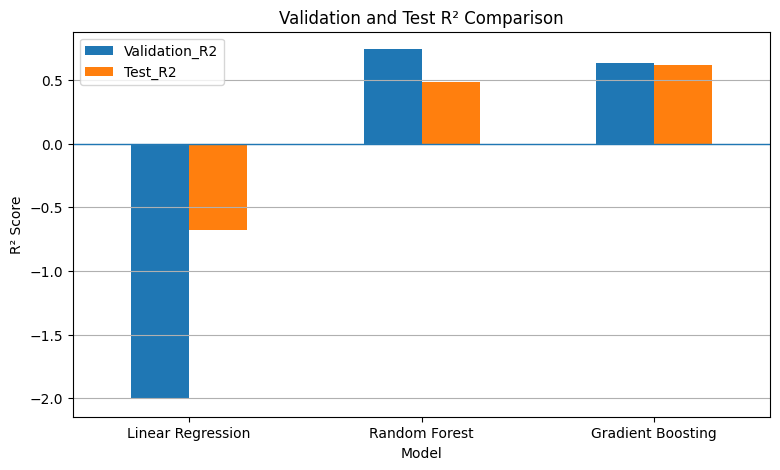

In [70]:
comparison_plot = results[
    ["Model", "Validation_R2", "Test_R2"]
].set_index("Model")

comparison_plot.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.axhline(
    y=0,
    linewidth=1
)

plt.ylabel("R² Score")
plt.xlabel("Model")
plt.title("Validation and Test R² Comparison")

plt.xticks(rotation=0)
plt.grid(axis="y")

plt.show()

In [71]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

test_dates = ml_data.loc[test_mask, "Date"].reset_index(drop=True)

prediction_2024 = pd.DataFrame({
    "Date": test_dates,
    "Actual_ML": np.array(y_test),
    "Predicted_ML": test_pred_gb
})

prediction_2024["Error_ML"] = (
    prediction_2024["Actual_ML"]
    - prediction_2024["Predicted_ML"]
)

prediction_2024["Absolute_Error_ML"] = (
    prediction_2024["Error_ML"].abs()
)

prediction_2024.round(2)

,Date,Actual_ML,Predicted_ML,Error_ML,Absolute_Error_ML
0,2024-01-01,114662.83,105388.45,9274.39,9274.39
1,2024-02-01,115655.09,73254.64,42400.45,42400.45
2,2024-03-01,44183.33,39537.82,4645.51,4645.51
3,2024-06-01,13769.08,19435.49,-5666.41,5666.41
4,2024-07-01,14458.62,14390.79,67.83,67.83
5,2024-08-01,9895.27,31872.28,-21977.01,21977.01
6,2024-09-01,30364.61,65647.22,-35282.61,35282.61
7,2024-10-01,59432.76,71894.01,-12461.25,12461.25
8,2024-11-01,11910.37,39105.56,-27195.19,27195.19
9,2024-12-01,4713.01,43727.56,-39014.55,39014.55


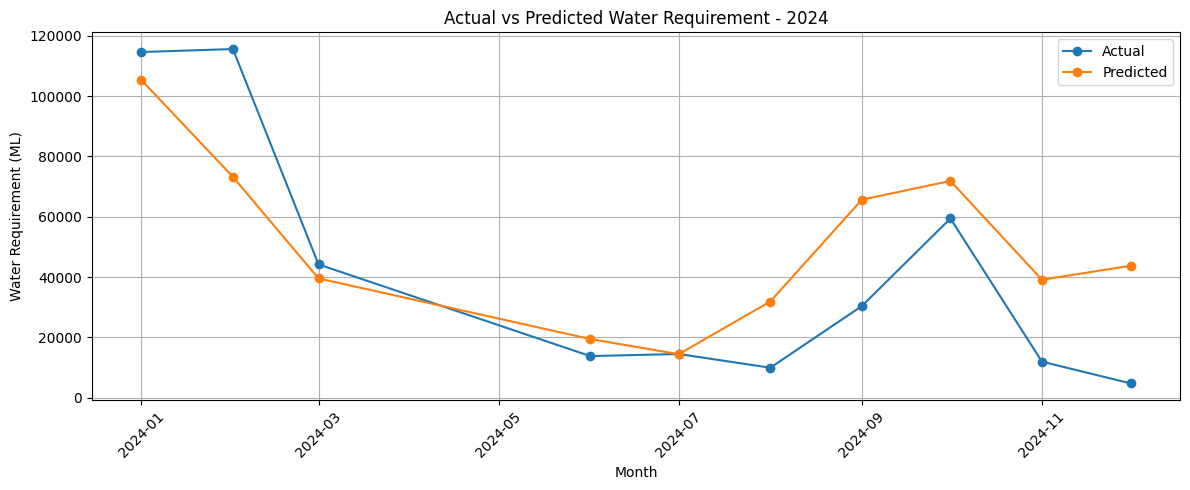

In [72]:
plt.figure(figsize=(12, 5))

plt.plot(
    prediction_2024["Date"],
    prediction_2024["Actual_ML"],
    marker="o",
    label="Actual"
)

plt.plot(
    prediction_2024["Date"],
    prediction_2024["Predicted_ML"],
    marker="o",
    label="Predicted"
)

plt.xlabel("Month")
plt.ylabel("Water Requirement (ML)")
plt.title(
    "Actual vs Predicted Water Requirement - 2024"
)

plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()

In [73]:
feature_importance = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": gb_model.feature_importances_
})

feature_importance = (
    feature_importance
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

feature_importance.round(4)

,Feature,Importance
0,Min_Temp_C,0.3771
1,Rainfall_mm,0.2164
2,Avg_Temp_C,0.1715
3,Reservoir_Inflow_Processed_Cusecs,0.0859
4,Month_Cos,0.0643
5,Month_Sin,0.0257
6,Reservoir_Monthly_Avg_Storage_pct,0.0206
7,Max_Temp_C,0.0151
8,GW_Level_Processed_m_bgl,0.0119
9,Avg_Humidity_pct,0.0087


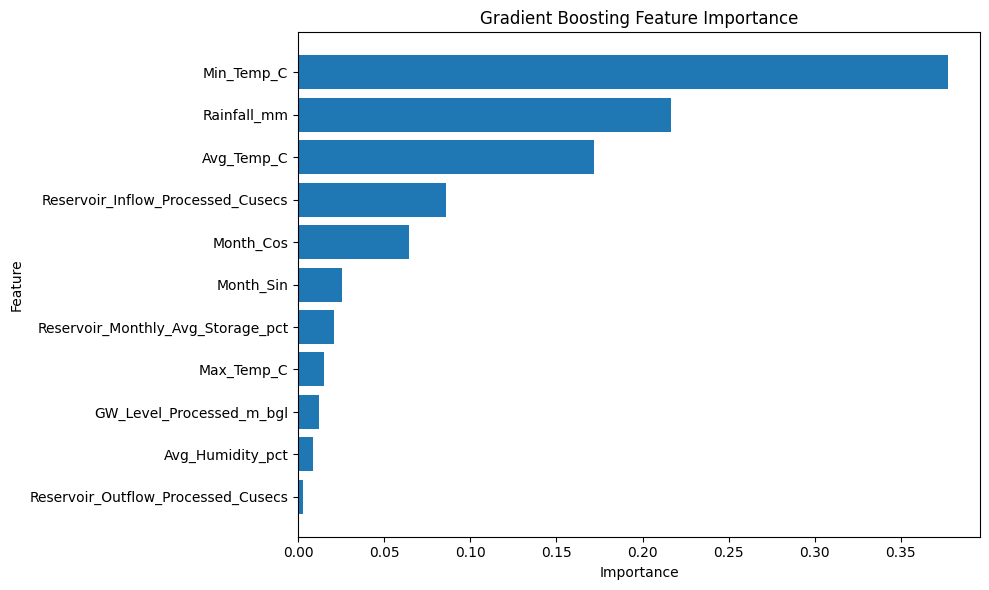

In [74]:
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title(
    "Gradient Boosting Feature Importance"
)

plt.gca().invert_yaxis()
plt.tight_layout()

plt.show()

In [75]:
if len(X_future) > 0:

    future_pred_gb = gb_model.predict(X_future)

    prediction_2025 = pd.DataFrame({
        "Date":
            ml_data.loc[
                future_mask,
                "Date"
            ].reset_index(drop=True),

        "Actual_Scenario_ML":
            np.array(y_future),

        "Predicted_ML":
            future_pred_gb
    })

    prediction_2025["Error_ML"] = (
        prediction_2025["Actual_Scenario_ML"]
        - prediction_2025["Predicted_ML"]
    )

    prediction_2025["Absolute_Error_ML"] = (
        prediction_2025["Error_ML"].abs()
    )

    print(
        prediction_2025.round(2)
    )

        Date  Actual_Scenario_ML  Predicted_ML  Error_ML  Absolute_Error_ML
0 2025-01-01           115473.12     105850.81   9622.31            9622.31
1 2025-02-01           135665.84      85378.48  50287.36           50287.36
2 2025-03-01             4725.78      65566.51 -60840.73           60840.73


In [76]:
if len(X_future) > 0:

    future_mae, future_rmse, future_r2, future_mape = (
        evaluate_model(
            y_future,
            future_pred_gb
        )
    )

    print("2025 AVAILABLE-MONTH DEMONSTRATION")
    print("----------------------------------")
    print("MAE :", round(future_mae, 2))
    print("RMSE:", round(future_rmse, 2))

    if len(y_future) >= 2:
        print("R²  :", round(future_r2, 4))

    print("MAPE:", round(future_mape, 2), "%")

2025 AVAILABLE-MONTH DEMONSTRATION
----------------------------------
MAE : 40250.13
RMSE: 45909.34
R²  : 0.3638
MAPE: 444.27 %


In [77]:
prediction_2024.to_csv(
    "Gradient_Boosting_2024_Predictions.csv",
    index=False
)

feature_importance.to_csv(
    "Gradient_Boosting_Feature_Importance.csv",
    index=False
)

if len(X_future) > 0:
    prediction_2025.to_csv(
        "Gradient_Boosting_2025_Demonstration.csv",
        index=False
    )

print("Results saved successfully.")

Results saved successfully.


In [78]:
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

anomaly_features = [
    "Rainfall_mm",
    "Avg_Temp_C",
    "Avg_Humidity_pct",
    "GW_Level_Processed_m_bgl",
    "Reservoir_Monthly_Avg_Storage_pct",
    "Reservoir_Inflow_Processed_Cusecs",
    "Reservoir_Outflow_Processed_Cusecs"
]

anomaly_features = [
    col for col in anomaly_features
    if col in monthly.columns
]

print("Anomaly features:")
print(anomaly_features)

Anomaly features:
['Rainfall_mm', 'Avg_Temp_C', 'Avg_Humidity_pct', 'GW_Level_Processed_m_bgl', 'Reservoir_Monthly_Avg_Storage_pct', 'Reservoir_Inflow_Processed_Cusecs', 'Reservoir_Outflow_Processed_Cusecs']


In [79]:
print(
    monthly[anomaly_features]
    .isna()
    .sum()
)

Rainfall_mm                           0
Avg_Temp_C                            0
Avg_Humidity_pct                      0
GW_Level_Processed_m_bgl              0
Reservoir_Monthly_Avg_Storage_pct     0
Reservoir_Inflow_Processed_Cusecs     0
Reservoir_Outflow_Processed_Cusecs    0
dtype: int64


In [80]:
anomaly_scaler = StandardScaler()

X_anomaly = anomaly_scaler.fit_transform(
    monthly[anomaly_features]
)

print("Anomaly dataset shape:", X_anomaly.shape)

Anomaly dataset shape: (132, 7)


In [81]:
iso_model = IsolationForest(
    n_estimators=300,
    contamination=0.05,
    random_state=42
)

monthly["Anomaly_Label"] = iso_model.fit_predict(
    X_anomaly
)

monthly["Anomaly_Score"] = (
    iso_model.decision_function(
        X_anomaly
    )
)

In [83]:
monthly["Anomaly_Status"] = np.where(
    monthly["Anomaly_Label"] == -1,
    "Anomaly",
    "Normal"
)

In [84]:
print(
    monthly["Anomaly_Status"]
    .value_counts()
)

Anomaly_Status
Normal     125
Anomaly      7
Name: count, dtype: int64


In [85]:
anomalies = monthly[
    monthly["Anomaly_Status"] == "Anomaly"
][
    [
        "Date",
        "Rainfall_mm",
        "Avg_Temp_C",
        "Avg_Humidity_pct",
        "GW_Level_Processed_m_bgl",
        "Reservoir_Monthly_Avg_Storage_pct",
        "Anomaly_Score"
    ]
].copy()

anomalies = anomalies.sort_values(
    "Anomaly_Score"
)

anomalies.round(2)

,Date,Rainfall_mm,Avg_Temp_C,Avg_Humidity_pct,GW_Level_Processed_m_bgl,Reservoir_Monthly_Avg_Storage_pct,Anomaly_Score
107,2023-12-01,498.1,28.55,82.5,2.82,99.68,-0.14
108,2024-01-01,19.8,26.85,82.5,0.85,92.30,-0.04
106,2023-11-01,48.3,27.80,84.5,4.80,94.91,-0.03
82,2021-11-01,405.1,27.70,88.0,1.20,85.56,-0.02
105,2023-10-01,48.3,28.15,83.5,5.86,90.15,-0.01
104,2023-09-01,35.5,31.30,74.0,6.92,85.39,-0.01
10,2015-11-01,384.2,27.15,86.0,2.98,95.36,-0.00


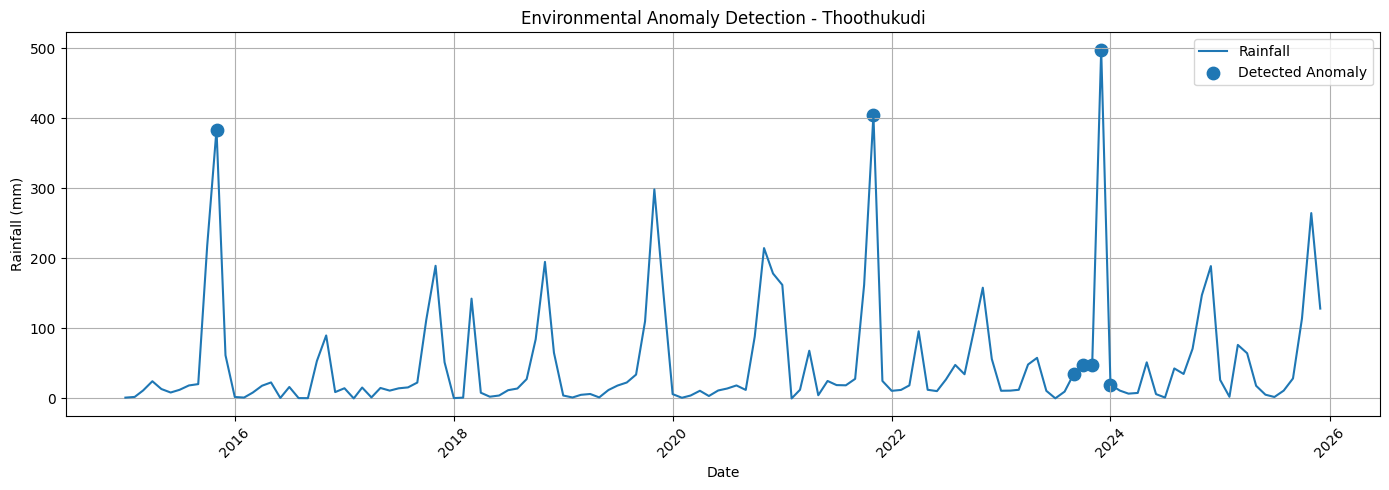

In [86]:
plt.figure(figsize=(14, 5))

plt.plot(
    monthly["Date"],
    monthly["Rainfall_mm"],
    label="Rainfall"
)

anomaly_rows = monthly[
    monthly["Anomaly_Status"] == "Anomaly"
]

plt.scatter(
    anomaly_rows["Date"],
    anomaly_rows["Rainfall_mm"],
    marker="o",
    s=80,
    label="Detected Anomaly"
)

plt.xlabel("Date")
plt.ylabel("Rainfall (mm)")
plt.title(
    "Environmental Anomaly Detection - Thoothukudi"
)

plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [87]:
stress_data = monthly.copy()

rain_q25 = stress_data["Rainfall_mm"].quantile(0.25)
rain_q75 = stress_data["Rainfall_mm"].quantile(0.75)

reservoir_q25 = stress_data[
    "Reservoir_Monthly_Avg_Storage_pct"
].quantile(0.25)

gw_q75 = stress_data[
    "GW_Level_Processed_m_bgl"
].quantile(0.75)

temp_q75 = stress_data[
    "Avg_Temp_C"
].quantile(0.75)

print("Water Stress Thresholds")
print("-----------------------")
print("Low rainfall threshold:", round(rain_q25, 2), "mm")
print("High rainfall threshold:", round(rain_q75, 2), "mm")
print("Low reservoir threshold:", round(reservoir_q25, 2), "%")
print("Deep groundwater threshold:", round(gw_q75, 2), "m bgl")
print("High temperature threshold:", round(temp_q75, 2), "°C")

Water Stress Thresholds
-----------------------
Low rainfall threshold: 8.35 mm
High rainfall threshold: 56.8 mm
Low reservoir threshold: 49.39 %
Deep groundwater threshold: 7.16 m bgl
High temperature threshold: 31.2 °C


In [88]:
stress_data["Stress_Score"] = 0

stress_data.loc[
    stress_data["Rainfall_mm"] <= rain_q25,
    "Stress_Score"
] += 1

stress_data.loc[
    stress_data["Reservoir_Monthly_Avg_Storage_pct"] <= reservoir_q25,
    "Stress_Score"
] += 1

stress_data.loc[
    stress_data["GW_Level_Processed_m_bgl"] >= gw_q75,
    "Stress_Score"
] += 1

stress_data.loc[
    stress_data["Avg_Temp_C"] >= temp_q75,
    "Stress_Score"
] += 1

In [89]:
stress_data["Water_Stress_Level"] = stress_data[
    "Stress_Score"
].map({
    0: "Low",
    1: "Moderate",
    2: "High",
    3: "Critical",
    4: "Critical"
})

print(
    stress_data["Water_Stress_Level"]
    .value_counts()
)

Water_Stress_Level
Low         55
Moderate    35
High        30
Critical    12
Name: count, dtype: int64


In [90]:
high_stress = stress_data[
    stress_data["Water_Stress_Level"].isin(
        ["High", "Critical"]
    )
][[
    "Date",
    "Rainfall_mm",
    "Avg_Temp_C",
    "GW_Level_Processed_m_bgl",
    "Reservoir_Monthly_Avg_Storage_pct",
    "Stress_Score",
    "Water_Stress_Level"
]]

print(
    high_stress
    .sort_values(
        ["Stress_Score", "Date"],
        ascending=[False, True]
    )
    .round(2)
)

          Date  Rainfall_mm  Avg_Temp_C  GW_Level_Processed_m_bgl  \
17  2016-06-01         0.70       31.25                      9.24   
20  2016-09-01         0.40       31.85                      9.69   
27  2017-04-01         1.50       31.20                     10.11   
16  2016-05-01        22.90       31.75                      8.97   
18  2016-07-01        16.40       31.60                      9.52   
19  2016-08-01         0.50       29.45                      9.79   
25  2017-02-01         0.04       27.35                      9.40   
28  2017-05-01        15.00       31.70                     10.47   
29  2017-06-01        11.20       31.65                     10.59   
41  2018-06-01         4.20       31.93                      6.24   
102 2023-07-01         0.20       32.55                      7.70   
114 2024-07-01         1.30       32.10                      3.80   
4   2015-05-01        13.50       31.95                      7.60   
5   2015-06-01         8.50       

In [91]:
def generate_recommendation(row):

    recommendations = []

    # Rainfall condition
    if row["Rainfall_mm"] <= rain_q25:
        recommendations.append(
            "Promote rainwater harvesting and reduce non-essential water use"
        )

    # Reservoir condition
    if row["Reservoir_Monthly_Avg_Storage_pct"] <= reservoir_q25:
        recommendations.append(
            "Prioritize essential supply and monitor reservoir releases"
        )

    # Groundwater condition
    if row["GW_Level_Processed_m_bgl"] >= gw_q75:
        recommendations.append(
            "Limit excessive groundwater extraction and promote recharge"
        )

    # Temperature condition
    if row["Avg_Temp_C"] >= temp_q75:
        recommendations.append(
            "Improve irrigation scheduling and reduce evaporation losses"
        )

    # No major stress condition
    if len(recommendations) == 0:
        recommendations.append(
            "Maintain normal water-use monitoring and conservation practices"
        )

    return "; ".join(recommendations)


stress_data["Conservation_Recommendation"] = (
    stress_data.apply(
        generate_recommendation,
        axis=1
    )
)

In [92]:
recommendation_results = stress_data[
    stress_data["Water_Stress_Level"].isin(
        ["High", "Critical"]
    )
][[
    "Date",
    "Stress_Score",
    "Water_Stress_Level",
    "Conservation_Recommendation"
]]

print(
    recommendation_results
    .sort_values(
        ["Stress_Score", "Date"],
        ascending=[False, True]
    )
    .to_string(index=False)
)

      Date  Stress_Score Water_Stress_Level                                                                                                                                                                                                                           Conservation_Recommendation
2016-06-01             4           Critical Promote rainwater harvesting and reduce non-essential water use; Prioritize essential supply and monitor reservoir releases; Limit excessive groundwater extraction and promote recharge; Improve irrigation scheduling and reduce evaporation losses
2016-09-01             4           Critical Promote rainwater harvesting and reduce non-essential water use; Prioritize essential supply and monitor reservoir releases; Limit excessive groundwater extraction and promote recharge; Improve irrigation scheduling and reduce evaporation losses
2017-04-01             4           Critical Promote rainwater harvesting and reduce non-essential water use; Prioritize essential 

In [93]:
action_map = {
    "Low": "Normal Monitoring",
    "Moderate": "Conservation Advisory",
    "High": "Water Conservation Alert",
    "Critical": "Immediate Water Management Action"
}

stress_data["Management_Action"] = (
    stress_data["Water_Stress_Level"]
    .map(action_map)
)

In [94]:
print(
    stress_data[
        [
            "Date",
            "Stress_Score",
            "Water_Stress_Level",
            "Management_Action"
        ]
    ].tail(24)
)

          Date  Stress_Score Water_Stress_Level  \
108 2024-01-01             0                Low   
109 2024-02-01             0                Low   
110 2024-03-01             1           Moderate   
111 2024-04-01             1           Moderate   
112 2024-05-01             0                Low   
113 2024-06-01             2               High   
114 2024-07-01             3           Critical   
115 2024-08-01             1           Moderate   
116 2024-09-01             0                Low   
117 2024-10-01             0                Low   
118 2024-11-01             0                Low   
119 2024-12-01             0                Low   
120 2025-01-01             0                Low   
121 2025-02-01             1           Moderate   
122 2025-03-01             0                Low   
123 2025-04-01             0                Low   
124 2025-05-01             1           Moderate   
125 2025-06-01             2               High   
126 2025-07-01             2   

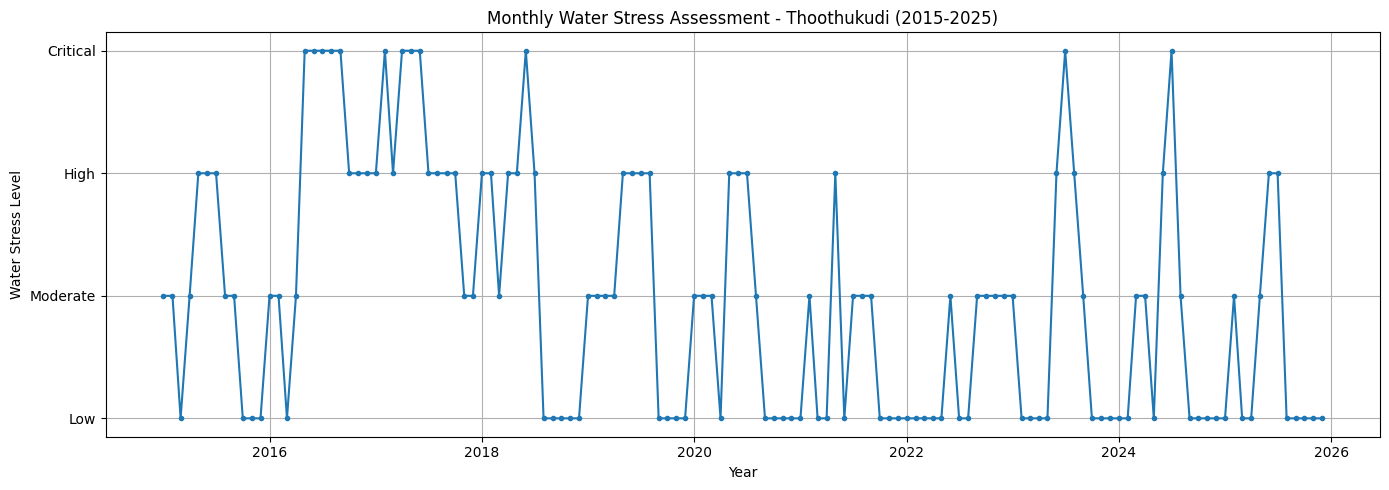

In [95]:
stress_numeric = {
    "Low": 0,
    "Moderate": 1,
    "High": 2,
    "Critical": 3
}

stress_data["Stress_Level_Numeric"] = (
    stress_data["Water_Stress_Level"]
    .map(stress_numeric)
)

plt.figure(figsize=(14, 5))

plt.plot(
    stress_data["Date"],
    stress_data["Stress_Level_Numeric"],
    marker="o",
    markersize=3
)

plt.yticks(
    [0, 1, 2, 3],
    ["Low", "Moderate", "High", "Critical"]
)

plt.xlabel("Year")
plt.ylabel("Water Stress Level")
plt.title(
    "Monthly Water Stress Assessment - Thoothukudi (2015-2025)"
)

plt.grid(True)
plt.tight_layout()
plt.show()

In [96]:
final_output = stress_data.copy()

final_output["Anomaly_Status"] = monthly["Anomaly_Status"].values
final_output["Anomaly_Score"] = monthly["Anomaly_Score"].values

In [97]:
final_output[
    [
        "Date",
        "Anomaly_Status",
        "Anomaly_Score",
        "Water_Stress_Level",
        "Management_Action"
    ]
].tail(24)

,Date,Anomaly_Status,Anomaly_Score,Water_Stress_Level,Management_Action
108,2024-01-01,Anomaly,-0.038723,Low,Normal Monitoring
109,2024-02-01,Normal,0.016409,Low,Normal Monitoring
110,2024-03-01,Normal,0.034693,Moderate,Conservation Advisory
111,2024-04-01,Normal,0.073252,Moderate,Conservation Advisory
112,2024-05-01,Normal,0.108754,Low,Normal Monitoring
113,2024-06-01,Normal,0.138044,High,Water Conservation Alert
114,2024-07-01,Normal,0.093734,Critical,Immediate Water Management Action
115,2024-08-01,Normal,0.095279,Moderate,Conservation Advisory
116,2024-09-01,Normal,0.107470,Low,Normal Monitoring
117,2024-10-01,Normal,0.095004,Low,Normal Monitoring


In [98]:
final_output["Predicted_Water_Requirement_ML"] = np.nan
final_output["Scenario_Water_Requirement_ML"] = np.nan
final_output["Prediction_Type"] = "Not evaluated"

In [99]:
for i, row in prediction_2024.iterrows():

    mask = (
        final_output["Date"]
        == pd.to_datetime(row["Date"])
    )

    final_output.loc[
        mask,
        "Scenario_Water_Requirement_ML"
    ] = row["Actual_ML"]

    final_output.loc[
        mask,
        "Predicted_Water_Requirement_ML"
    ] = row["Predicted_ML"]

    final_output.loc[
        mask,
        "Prediction_Type"
    ] = "2024 Unseen Test Prediction"

In [100]:
if "prediction_2025" in globals():

    for i, row in prediction_2025.iterrows():

        mask = (
            final_output["Date"]
            == pd.to_datetime(row["Date"])
        )

        final_output.loc[
            mask,
            "Scenario_Water_Requirement_ML"
        ] = row["Actual_Scenario_ML"]

        final_output.loc[
            mask,
            "Predicted_Water_Requirement_ML"
        ] = row["Predicted_ML"]

        final_output.loc[
            mask,
            "Prediction_Type"
        ] = "2025 Available-Month Demonstration"

In [101]:
def system_status(row):

    if row["Water_Stress_Level"] == "Critical":
        return "Critical Water Stress"

    elif row["Water_Stress_Level"] == "High":
        return "High Water Stress"

    elif row["Anomaly_Status"] == "Anomaly":
        return "Unusual Environmental Condition"

    elif row["Water_Stress_Level"] == "Moderate":
        return "Moderate Water Stress"

    else:
        return "Normal Water Condition"


final_output["System_Status"] = final_output.apply(
    system_status,
    axis=1
)

In [102]:
final_decision_table = final_output[
    [
        "Date",
        "Rainfall_mm",
        "Avg_Temp_C",
        "Avg_Humidity_pct",
        "GW_Level_Processed_m_bgl",
        "Reservoir_Monthly_Avg_Storage_pct",

        "Scenario_Water_Requirement_ML",
        "Predicted_Water_Requirement_ML",
        "Prediction_Type",

        "Anomaly_Status",
        "Anomaly_Score",

        "Stress_Score",
        "Water_Stress_Level",

        "System_Status",
        "Management_Action",
        "Conservation_Recommendation"
    ]
].copy()

In [103]:
final_decision_table[
    final_decision_table["Date"].dt.year >= 2024
].round(2)

,Date,Rainfall_mm,Avg_Temp_C,Avg_Humidity_pct,GW_Level_Processed_m_bgl,Reservoir_Monthly_Avg_Storage_pct,Scenario_Water_Requirement_ML,Predicted_Water_Requirement_ML,Prediction_Type,Anomaly_Status,Anomaly_Score,Stress_Score,Water_Stress_Level,System_Status,Management_Action,Conservation_Recommendation
108,2024-01-01,19.8,26.85,82.5,0.85,92.30,114662.83,105388.45,2024 Unseen Test Prediction,Anomaly,-0.04,0,Low,Unusual Environmental Condition,Normal Monitoring,Maintain normal water-use monitoring and conse...
109,2024-02-01,11.3,27.95,80.5,1.41,84.93,115655.09,73254.64,2024 Unseen Test Prediction,Normal,0.02,0,Low,Normal Water Condition,Normal Monitoring,Maintain normal water-use monitoring and conse...
110,2024-03-01,6.9,28.60,81.5,1.98,77.56,44183.33,39537.82,2024 Unseen Test Prediction,Normal,0.03,1,Moderate,Moderate Water Stress,Conservation Advisory,Promote rainwater harvesting and reduce non-es...
111,2024-04-01,7.9,29.65,76.5,2.54,70.19,NaN,NaN,Not evaluated,Normal,0.07,1,Moderate,Moderate Water Stress,Conservation Advisory,Promote rainwater harvesting and reduce non-es...
112,2024-05-01,51.6,30.70,74.0,3.10,62.81,NaN,NaN,Not evaluated,Normal,0.11,0,Low,Normal Water Condition,Normal Monitoring,Maintain normal water-use monitoring and conse...
113,2024-06-01,6.2,32.15,71.5,3.45,55.44,13769.08,19435.49,2024 Unseen Test Prediction,Normal,0.14,2,High,High Water Stress,Water Conservation Alert,Promote rainwater harvesting and reduce non-es...
114,2024-07-01,1.3,32.10,63.0,3.80,48.07,14458.62,14390.79,2024 Unseen Test Prediction,Normal,0.09,3,Critical,Critical Water Stress,Immediate Water Management Action,Promote rainwater harvesting and reduce non-es...
115,2024-08-01,42.9,31.40,67.5,4.15,51.13,9895.27,31872.28,2024 Unseen Test Prediction,Normal,0.10,1,Moderate,Moderate Water Stress,Conservation Advisory,Improve irrigation scheduling and reduce evapo...
116,2024-09-01,35.0,31.15,69.0,3.41,54.18,30364.61,65647.22,2024 Unseen Test Prediction,Normal,0.11,0,Low,Normal Water Condition,Normal Monitoring,Maintain normal water-use monitoring and conse...
117,2024-10-01,71.1,29.70,80.5,2.66,57.24,59432.76,71894.01,2024 Unseen Test Prediction,Normal,0.10,0,Low,Normal Water Condition,Normal Monitoring,Maintain normal water-use monitoring and conse...


In [104]:
final_decision_table.to_csv(
    "Smart_Water_Management_Final_Output.csv",
    index=False
)

print("Final decision-support dataset saved successfully.")

Final decision-support dataset saved successfully.


In [105]:
train_pred_gb = gb_model.predict(X_train)

train_residuals = (
    y_train.values - train_pred_gb
)

In [106]:
q1 = np.percentile(train_residuals, 25)
q3 = np.percentile(train_residuals, 75)

iqr = q3 - q1

lower_residual_limit = q1 - 1.5 * iqr
upper_residual_limit = q3 + 1.5 * iqr

print("Residual Anomaly Thresholds")
print("---------------------------")
print(
    "Lower:",
    round(lower_residual_limit, 2),
    "ML"
)

print(
    "Upper:",
    round(upper_residual_limit, 2),
    "ML"
)

Residual Anomaly Thresholds
---------------------------
Lower: -3268.98 ML
Upper: 2865.22 ML


In [107]:
prediction_2024[
    "Residual_ML"
] = (
    prediction_2024["Actual_ML"]
    - prediction_2024["Predicted_ML"]
)

prediction_2024[
    "Demand_Anomaly"
] = np.where(
    (
        prediction_2024["Residual_ML"]
        < lower_residual_limit
    )
    |
    (
        prediction_2024["Residual_ML"]
        > upper_residual_limit
    ),
    "Anomaly",
    "Normal"
)

prediction_2024[
    [
        "Date",
        "Actual_ML",
        "Predicted_ML",
        "Residual_ML",
        "Demand_Anomaly"
    ]
].round(2)

,Date,Actual_ML,Predicted_ML,Residual_ML,Demand_Anomaly
0,2024-01-01,114662.83,105388.45,9274.39,Anomaly
1,2024-02-01,115655.09,73254.64,42400.45,Anomaly
2,2024-03-01,44183.33,39537.82,4645.51,Anomaly
3,2024-06-01,13769.08,19435.49,-5666.41,Anomaly
4,2024-07-01,14458.62,14390.79,67.83,Normal
5,2024-08-01,9895.27,31872.28,-21977.01,Anomaly
6,2024-09-01,30364.61,65647.22,-35282.61,Anomaly
7,2024-10-01,59432.76,71894.01,-12461.25,Anomaly
8,2024-11-01,11910.37,39105.56,-27195.19,Anomaly
9,2024-12-01,4713.01,43727.56,-39014.55,Anomaly


In [108]:
print("Training Residual Thresholds")
print("----------------------------")
print("Q1:", round(q1, 2))
print("Q3:", round(q3, 2))
print("IQR:", round(iqr, 2))
print("Lower limit:", round(lower_residual_limit, 2))
print("Upper limit:", round(upper_residual_limit, 2))

print("\n2024 anomaly count:")
print(prediction_2024["Demand_Anomaly"].value_counts())

Training Residual Thresholds
----------------------------
Q1: -968.66
Q3: 564.89
IQR: 1533.55
Lower limit: -3268.98
Upper limit: 2865.22

2024 anomaly count:
Demand_Anomaly
Anomaly    9
Normal     1
Name: count, dtype: int64


In [109]:
val_pred_gb = gb_model.predict(X_val)

val_residuals = (
    y_val.values - val_pred_gb
)

validation_residual_table = pd.DataFrame({
    "Date": ml_data.loc[val_mask, "Date"].values,
    "Actual_ML": y_val.values,
    "Predicted_ML": val_pred_gb,
    "Residual_ML": val_residuals
})

print(
    validation_residual_table.round(2)
)

        Date  Actual_ML  Predicted_ML  Residual_ML
0 2023-01-01  131047.41      73717.11     57330.30
1 2023-02-01  119822.93     111002.19      8820.74
2 2023-03-01   40143.35      39770.03       373.32
3 2023-06-01   13878.79      15787.34     -1908.55
4 2023-07-01   15290.96      14694.08       596.87
5 2023-08-01   14160.00      16848.14     -2688.15
6 2023-09-01   32957.21      39582.64     -6625.42
7 2023-10-01   79178.05      58120.86     21057.19
8 2023-11-01   79026.43      58636.11     20390.32
9 2023-12-01    4700.24      57394.98    -52694.75


In [110]:
val_residual_mean = np.mean(val_residuals)
val_residual_std = np.std(
    val_residuals,
    ddof=1
)

print("\nValidation Residual Statistics")
print("------------------------------")
print(
    "Mean:",
    round(val_residual_mean, 2),
    "ML"
)

print(
    "Standard deviation:",
    round(val_residual_std, 2),
    "ML"
)


Validation Residual Statistics
------------------------------
Mean: 4465.19 ML
Standard deviation: 27601.04 ML


In [111]:
lower_deviation_limit = (
    val_residual_mean
    - 2 * val_residual_std
)

upper_deviation_limit = (
    val_residual_mean
    + 2 * val_residual_std
)

print("\nRequirement Deviation Thresholds")
print("--------------------------------")
print(
    "Lower limit:",
    round(lower_deviation_limit, 2),
    "ML"
)

print(
    "Upper limit:",
    round(upper_deviation_limit, 2),
    "ML"
)


Requirement Deviation Thresholds
--------------------------------
Lower limit: -50736.89 ML
Upper limit: 59667.27 ML


In [112]:
prediction_2024["Requirement_Deviation"] = np.where(
    (
        prediction_2024["Residual_ML"]
        < lower_deviation_limit
    )
    |
    (
        prediction_2024["Residual_ML"]
        > upper_deviation_limit
    ),
    "Unusual",
    "Normal"
)

print(
    prediction_2024[
        [
            "Date",
            "Actual_ML",
            "Predicted_ML",
            "Residual_ML",
            "Requirement_Deviation"
        ]
    ].round(2)
)

print("\nDeviation Count:")
print(
    prediction_2024[
        "Requirement_Deviation"
    ].value_counts()
)

        Date  Actual_ML  Predicted_ML  Residual_ML Requirement_Deviation
0 2024-01-01  114662.83     105388.45      9274.39                Normal
1 2024-02-01  115655.09      73254.64     42400.45                Normal
2 2024-03-01   44183.33      39537.82      4645.51                Normal
3 2024-06-01   13769.08      19435.49     -5666.41                Normal
4 2024-07-01   14458.62      14390.79        67.83                Normal
5 2024-08-01    9895.27      31872.28    -21977.01                Normal
6 2024-09-01   30364.61      65647.22    -35282.61                Normal
7 2024-10-01   59432.76      71894.01    -12461.25                Normal
8 2024-11-01   11910.37      39105.56    -27195.19                Normal
9 2024-12-01    4713.01      43727.56    -39014.55                Normal

Deviation Count:
Requirement_Deviation
Normal    10
Name: count, dtype: int64


In [113]:
prediction_2024["Absolute_Deviation_ML"] = (
    prediction_2024["Actual_ML"]
    - prediction_2024["Predicted_ML"]
).abs()

prediction_2024["Deviation_pct"] = np.where(
    prediction_2024["Actual_ML"] != 0,
    (
        prediction_2024["Absolute_Deviation_ML"]
        / prediction_2024["Actual_ML"]
    ) * 100,
    np.nan
)

prediction_2024[
    [
        "Date",
        "Actual_ML",
        "Predicted_ML",
        "Residual_ML",
        "Absolute_Deviation_ML",
        "Deviation_pct"
    ]
].round(2)

,Date,Actual_ML,Predicted_ML,Residual_ML,Absolute_Deviation_ML,Deviation_pct
0,2024-01-01,114662.83,105388.45,9274.39,9274.39,8.09
1,2024-02-01,115655.09,73254.64,42400.45,42400.45,36.66
2,2024-03-01,44183.33,39537.82,4645.51,4645.51,10.51
3,2024-06-01,13769.08,19435.49,-5666.41,5666.41,41.15
4,2024-07-01,14458.62,14390.79,67.83,67.83,0.47
5,2024-08-01,9895.27,31872.28,-21977.01,21977.01,222.10
6,2024-09-01,30364.61,65647.22,-35282.61,35282.61,116.20
7,2024-10-01,59432.76,71894.01,-12461.25,12461.25,20.97
8,2024-11-01,11910.37,39105.56,-27195.19,27195.19,228.33
9,2024-12-01,4713.01,43727.56,-39014.55,39014.55,827.81


In [114]:
if "Demand_Anomaly" in prediction_2024.columns:
    prediction_2024.drop(
        columns=["Demand_Anomaly"],
        inplace=True
    )

if "Requirement_Deviation" in prediction_2024.columns:
    prediction_2024.drop(
        columns=["Requirement_Deviation"],
        inplace=True
    )

In [115]:
final_output = stress_data.copy()

final_output["Environmental_Anomaly"] = (
    monthly["Anomaly_Status"].values
)

final_output["Environmental_Anomaly_Score"] = (
    monthly["Anomaly_Score"].values
)

In [116]:
def final_system_status(row):

    if row["Water_Stress_Level"] == "Critical":
        return "Critical Water Stress"

    elif row["Water_Stress_Level"] == "High":
        return "High Water Stress"

    elif row["Environmental_Anomaly"] == "Anomaly":
        return "Unusual Environmental Condition"

    elif row["Water_Stress_Level"] == "Moderate":
        return "Moderate Water Stress"

    else:
        return "Normal Water Condition"


final_output["System_Status"] = final_output.apply(
    final_system_status,
    axis=1
)

In [117]:
print("FINAL SYSTEM STATUS")
print("-------------------")

print(
    final_output["System_Status"]
    .value_counts()
)

FINAL SYSTEM STATUS
-------------------
System_Status
Normal Water Condition             49
Moderate Water Stress              34
High Water Stress                  30
Critical Water Stress              12
Unusual Environmental Condition     7
Name: count, dtype: int64


In [118]:
important_months = final_output[
    final_output["System_Status"]
    != "Normal Water Condition"
][[
    "Date",
    "Rainfall_mm",
    "Avg_Temp_C",
    "GW_Level_Processed_m_bgl",
    "Reservoir_Monthly_Avg_Storage_pct",
    "Environmental_Anomaly",
    "Stress_Score",
    "Water_Stress_Level",
    "System_Status",
    "Management_Action",
    "Conservation_Recommendation"
]]

important_months.tail(30)

,Date,Rainfall_mm,Avg_Temp_C,GW_Level_Processed_m_bgl,Reservoir_Monthly_Avg_Storage_pct,Environmental_Anomaly,Stress_Score,Water_Stress_Level,System_Status,Management_Action,Conservation_Recommendation
67,2020-08-01,18.6,30.85,7.800000,64.820000,Normal,1,Moderate,Moderate Water Stress,Conservation Advisory,Limit excessive groundwater extraction and pro...
73,2021-02-01,0.0,27.30,2.737500,68.193750,Normal,1,Moderate,Moderate Water Stress,Conservation Advisory,Promote rainwater harvesting and reduce non-es...
76,2021-05-01,4.6,31.70,5.100000,73.982500,Normal,2,High,High Water Stress,Water Conservation Alert,Promote rainwater harvesting and reduce non-es...
78,2021-07-01,19.1,31.55,5.646667,77.841667,Normal,1,Moderate,Moderate Water Stress,Conservation Advisory,Improve irrigation scheduling and reduce evapo...
79,2021-08-01,18.8,31.85,5.920000,79.771250,Normal,1,Moderate,Moderate Water Stress,Conservation Advisory,Improve irrigation scheduling and reduce evapo...
80,2021-09-01,28.0,31.95,4.346667,81.700833,Normal,1,Moderate,Moderate Water Stress,Conservation Advisory,Improve irrigation scheduling and reduce evapo...
82,2021-11-01,405.1,27.70,1.200000,85.560000,Anomaly,0,Low,Unusual Environmental Condition,Normal Monitoring,Maintain normal water-use monitoring and conse...
89,2022-06-01,10.5,31.85,4.681250,57.691250,Normal,1,Moderate,Moderate Water Stress,Conservation Advisory,Improve irrigation scheduling and reduce evapo...
92,2022-09-01,34.6,30.35,4.775000,45.747500,Normal,1,Moderate,Moderate Water Stress,Conservation Advisory,Prioritize essential supply and monitor reserv...
93,2022-10-01,94.3,29.20,4.806250,41.766250,Normal,1,Moderate,Moderate Water Stress,Conservation Advisory,Prioritize essential supply and monitor reserv...
